# APRAU 2026/27 - Grupo 08
## Parte 2, Tarefa 6: Generalized Additive Models (GAM)

**O que a tarefa pede (secção 6 do enunciado):** classificação binária com GAM, em estratégia *One-vs-Rest*: para cada uma das três classes (`N`, `HY`, `DI`) constrói-se um modelo que a distingue das outras duas, validado com validação cruzada.

1. Construir e avaliar os três modelos *One-vs-Rest*, apresentar os resultados de forma comparável e escolher a hipótese mais relevante para uma análise detalhada, justificando o critério.
2. Para o modelo escolhido, analisar a relação estimada entre cada preditor e a resposta: que preditores têm efeitos não lineares e se isso é consistente com a EDA (tarefa 2).
3. Comparar o GAM escolhido com uma regressão logística linear no mesmo problema binário: a flexibilidade adicional melhora os resultados?

**Verificação adicional (indicação do professor, secção 6.4):** um GAM é flexível e não deve estar a «decorar» os dados de treino. Mede-se a perda de desempenho do treino para a validação e para o teste (critério: inferior a 10%) e fazem-se controlos para perceber se um desempenho muito alto é sobreajuste ou de um sinal forte nos dados.

**Regra do enunciado:** usar os preditores mais relevantes segundo a seleção de variáveis da tarefa 5 (Ridge e Lasso).

**Biblioteca:** `pygam` (instalar com `pip install pygam`). Um GAM logístico modela

$$\operatorname{logit} P(Y=1) = \beta_0 + f_1(x_1) + f_2(x_2) + \dots + f_p(x_p)$$

em que cada $f_j$ é uma função suave estimada a partir dos dados (*spline* penalizada). Se todas as $f_j$ forem retas, o modelo reduz-se à regressão logística.

### Importações, dados e partição treino/teste

Codificação das variáveis categóricas e partição idênticas às das tarefas 4 e 5 (80% treino, 20% teste, estratificada, `random_state=42`), para que os resultados sejam comparáveis. O conjunto de teste só é usado na secção 6.3.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from pygam import LogisticGAM, f, l, s

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", message=".*p-values.*")
warnings.filterwarnings("ignore", category=RuntimeWarning, module="pygam")

df = pd.read_csv(Path("dataset_grupo_08.csv"))

mappings = {
    "bmi_level": {"Underweight": 1, "Normal": 2, "Overweight": 3, "Obese": 4},
    "physical_activity": {"Low": 1, "Moderate": 2, "High": 3},
    "stress_level": {"Low": 1, "Medium": 2, "High": 3},
    "sugar_consumption": {"Low": 1, "Medium": 2, "High": 3},
    "gender": {"Male": 0, "Female": 1},
    "family_history": {"No": 0, "Yes": 1},
    "low_hdl_cholesterol": {"No": 0, "Yes": 1},
    "high_ldl_cholesterol": {"No": 0, "Yes": 1},
}
one_hot = ["age_level", "smoking", "education_level", "employment_status"]

model_df = df.copy()
for col, mapping in mappings.items():
    model_df[col] = model_df[col].map(mapping)
model_df = pd.get_dummies(model_df, columns=one_hot, dtype=int)

y = model_df["target_class"]
X = model_df.drop(columns=["target_class", "target_regression"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
CLASSES = ["N", "HY", "DI"]
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print(y_train.value_counts().reindex(CLASSES).to_dict())

Treino: (1600, 42) | Teste: (400, 42)
{'N': 798, 'HY': 535, 'DI': 267}


### 6.0 Preditores (a partir da tarefa 5)

O enunciado manda usar os preditores mais relevantes segundo a seleção de variáveis da tarefa 5. Repete-se aqui o **Lasso** (regressão logística com penalização L1, ajustado só no treino) com `C = 0.05`, o valor escolhido na tarefa 5 por validação cruzada no treino, e mantêm-se as variáveis com coeficiente não nulo em pelo menos uma classe. Com este `C` o Lasso é mais exigente: mantém 18 variáveis (a versão anterior deste notebook, com `C = 0.1`, ficava com 26 preditores). A penalização L1 é indicada explicitamente (`penalty="l1"`), porque no scikit-learn 1.7 o `l1_ratio` sozinho é ignorado e o modelo seria uma regressão logística L2.

O mapa de calor mostra o coeficiente de cada variável em cada classe. Para `DI` o Lasso usa quase só `HbA1c_level` (coeficiente 3,6, em variáveis padronizadas); para `N` entram várias variáveis, com mais peso em `triglycerides` e `smoking_Current`; para `HY` os coeficientes são todos muito pequenos.

Duas variáveis do Lasso são retiradas por serem redundantes, pelos motivos já identificados na EDA (secção 5.2):

- `age_normalized` é a idade em escala 0-1 (r = 1 com `age`);
- `age_level_*` são categorizações de `age` (aqui, `age_level_Young`); num GAM a idade já entra com uma curva livre, e manter as duas versões repartiria o efeito entre elas.

Ficam 16 preditores: 6 contínuos, 3 ordinais e 7 binários. Cada preditor entra no GAM com o termo adequado ao seu tipo: **`s()`** (*spline*, curva livre) nos contínuos, **`f()`** (um efeito por nível) nos ordinais de 3-4 níveis e **`l()`** (linear) nos binários, onde uma curva não faz sentido.

Variáveis: 42 -> Lasso (C = 0.05): 18 -> sem redundantes: 16


,termo,valores distintos
bmi_level,f,4
physical_activity,f,3
sugar_consumption,f,3
gender,l,2
family_history,l,2
high_ldl_cholesterol,l,2
smoking_Current,l,2
smoking_Never,l,2
education_level_Primary,l,2
education_level_Tertiary,l,2


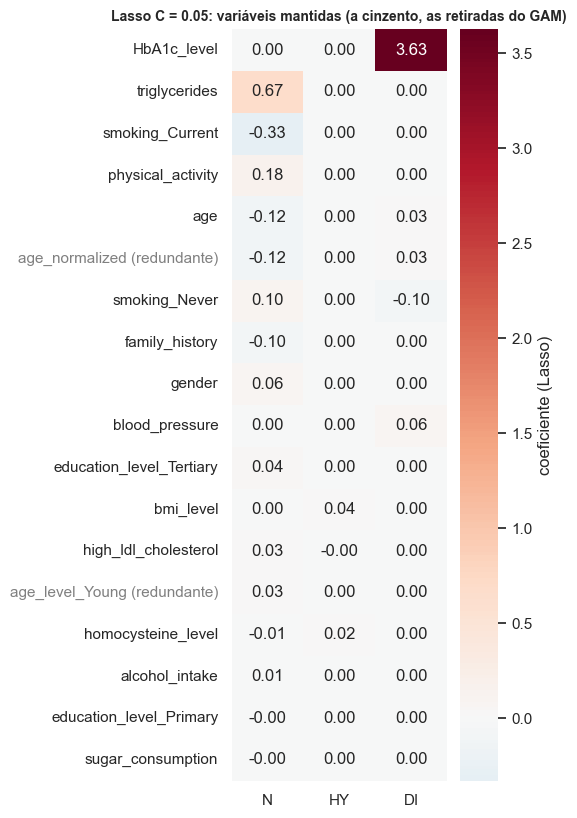

In [2]:
# penalty="l1" explícito: no scikit-learn 1.7 o l1_ratio é ignorado sem penalty="elasticnet"
# C = 0.05 é o valor escolhido por validação cruzada estratificada no treino na tarefa 5
LASSO_C = 0.05
lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(penalty="l1", solver="saga", C=LASSO_C,
                                 max_iter=20000, random_state=RANDOM_STATE)),
])
lasso.fit(X_train, y_train)
coef = lasso.named_steps["model"].coef_
lasso_selected = X.columns[np.abs(coef).sum(axis=0) > 0].tolist()

redundant = ["age_normalized", "age_level_Young", "age_level_Mature", "age_level_Senior"]
predictors = [c for c in lasso_selected if c not in redundant]
print(f"Variáveis: {X.shape[1]} -> Lasso (C = {LASSO_C}): {len(lasso_selected)} -> sem redundantes: {len(predictors)}")


def term_type(col):
    n_unique = X_train[col].nunique()
    if n_unique > 10:
        return "s"
    if n_unique > 2:
        return "f"
    return "l"


TERM_TYPES = {col: term_type(col) for col in predictors}
display(
    pd.DataFrame({
        "termo": pd.Series(TERM_TYPES),
        "valores distintos": X_train[predictors].nunique(),
    }).sort_values(["termo", "valores distintos"], ascending=[True, False])
)

# Coeficientes do Lasso (variáveis padronizadas), uma coluna por classe
coef_df = pd.DataFrame(coef.T, index=X.columns, columns=lasso.named_steps["model"].classes_)[CLASSES]
coef_df = coef_df.loc[lasso_selected]
coef_df = coef_df.loc[coef_df.abs().max(axis=1).sort_values(ascending=False).index]
coef_df.index = [f"{c} (redundante)" if c in redundant else c for c in coef_df.index]
fig, ax = plt.subplots(figsize=(5.5, 0.38 * len(coef_df) + 1.5))
sns.heatmap(coef_df, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "coeficiente (Lasso)"}, ax=ax)
for label in ax.get_yticklabels():
    if "(redundante)" in label.get_text():
        label.set_color("grey")
ax.set_title(f"Lasso C = {LASSO_C}: variáveis mantidas (a cinzento, as retiradas do GAM)", fontweight="bold", fontsize=10)
plt.tight_layout()
plt.show()


### 6.1 Os três modelos *One-vs-Rest*

**Validação.** Validação cruzada estratificada de 5 partes repetida 3 vezes (15 ajustes por modelo), no conjunto de treino. As partições são estratificadas pela classe original (3 classes) e são as **mesmas** para as três hipóteses e para o GAM e a regressão logística, o que permite comparações emparelhadas.

**Suavização.** O parâmetro de penalização $\lambda$ dos GAM é escolhido por `gridsearch` (grelha de 5 valores entre 0,1 e 1000) **dentro de cada partição de treino**, sem olhar à partição de validação.

**Métricas.** `ROC-AUC` e `PR-AUC` (não dependem do limiar), mais `Balanced accuracy`, `F1`, `Recall` e `Precision` da classe positiva com limiar 0,5, e `Log-loss` (qualidade das probabilidades). Como cada hipótese tem uma prevalência diferente (50%, 33%, 17%), a exatidão simples não é adequada.

**Critério de escolha da hipótese:** maior `ROC-AUC` médio na validação cruzada. A AUC não depende da prevalência da classe, ao contrário da `PR-AUC`, do `F1` e da `Precision`, e por isso é a métrica que permite comparar as três hipóteses entre si.

In [3]:
LAM_GRID = np.logspace(-1, 3, 5)
N_SPLINES = 10
METRICS = ["ROC-AUC", "PR-AUC", "Balanced accuracy", "F1", "Recall", "Precision", "Log-loss"]


def build_terms(cols, linear=()):
    makers = {"s": lambda j: s(j, n_splines=N_SPLINES), "f": f, "l": l}
    kinds = ["l" if col in linear else TERM_TYPES[col] for col in cols]
    terms = makers[kinds[0]](0)
    for j, kind in enumerate(kinds[1:], start=1):
        terms = terms + makers[kind](j)
    return terms


def fit_gam(X_fit, y_fit, linear=()):
    """GAM logístico; as colunas em `linear` passam de curva (s) a reta (l)."""
    gam = LogisticGAM(build_terms(list(X_fit.columns), linear), max_iter=200)
    return gam.gridsearch(X_fit.values, y_fit, lam=LAM_GRID, progress=False)


def corrected_ttest(d, n_test_over_train=1 / 4):
    """Teste t corrigido (Nadeau e Bengio) para diferenças entre partições que partilham dados."""
    k = len(d)
    se = np.sqrt((1 / k + n_test_over_train) * d.var(ddof=1))
    if se == 0:
        return np.nan, 1.0
    t_stat = d.mean() / se
    return t_stat, 2 * stats.t.sf(abs(t_stat), df=k - 1)


def make_lr():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ])


def binary_metrics(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "Balanced accuracy": balanced_accuracy_score(y_true, pred),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Log-loss": log_loss(y_true, proba),
    }

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
Xp = X_train[predictors].reset_index(drop=True)
y_cv = y_train.reset_index(drop=True)

rows, rows_train, fit_info = [], [], []
oof = {}  # previsões fora da amostra da 1.ª repetição (5 partições disjuntas): (classe, modelo) -> [(índices, probabilidades)]
for fold, (idx_tr, idx_va) in enumerate(cv.split(Xp, y_cv)):
    for cls in CLASSES:
        yb = (y_cv == cls).astype(int).values
        gam = fit_gam(Xp.iloc[idx_tr], yb[idx_tr])
        lr = make_lr().fit(Xp.iloc[idx_tr], yb[idx_tr])
        fit_info.append({"fold": fold, "classe": cls, "lambda": float(gam.lam[0][0]),
                         "EDoF": float(gam.statistics_["edof"])})
        probas = {
            "GAM": gam.predict_proba(Xp.iloc[idx_va].values),
            "LR": lr.predict_proba(Xp.iloc[idx_va])[:, 1],
        }
        probas_train = {
            "GAM": gam.predict_proba(Xp.iloc[idx_tr].values),
            "LR": lr.predict_proba(Xp.iloc[idx_tr])[:, 1],
        }
        for name in probas:
            rows.append({"fold": fold, "classe": cls, "modelo": name,
                         **binary_metrics(yb[idx_va], probas[name])})
            rows_train.append({"fold": fold, "classe": cls, "modelo": name,
                               **binary_metrics(yb[idx_tr], probas_train[name])})
            if fold < 5:
                oof.setdefault((cls, name), []).append((idx_va, probas[name]))

cv_results = pd.DataFrame(rows)
cv_train = pd.DataFrame(rows_train)
fit_info = pd.DataFrame(fit_info)
print("Ajustes:", cv_results.groupby(["classe", "modelo"]).size().iloc[0], "por modelo e classe")


def oof_arrays(cls, model):
    """Etiquetas e probabilidades fora da amostra (cada observação do treino aparece uma vez)."""
    idx = np.concatenate([i for i, _ in oof[(cls, model)]])
    proba = np.concatenate([p for _, p in oof[(cls, model)]])
    return (y_cv == cls).astype(int).values[idx], proba


Ajustes: 15 por modelo e classe


GAM One-vs-Rest, validação cruzada 5x3 (média ± desvio-padrão por partição):


,Prevalência,ROC-AUC,PR-AUC,Balanced accuracy,F1,Recall,Precision,Log-loss
N vs resto,49.9 %,0.869 ± 0.015,0.882 ± 0.013,0.803 ± 0.019,0.797 ± 0.02,0.776 ± 0.029,0.82 ± 0.025,0.44 ± 0.022
HY vs resto,33.4 %,0.868 ± 0.016,0.668 ± 0.035,0.821 ± 0.023,0.754 ± 0.027,0.817 ± 0.038,0.701 ± 0.027,0.406 ± 0.029
DI vs resto,16.7 %,0.988 ± 0.008,0.973 ± 0.012,0.946 ± 0.015,0.929 ± 0.018,0.9 ± 0.031,0.96 ± 0.031,0.074 ± 0.021


Hipótese escolhida (maior ROC-AUC médio): DI vs resto


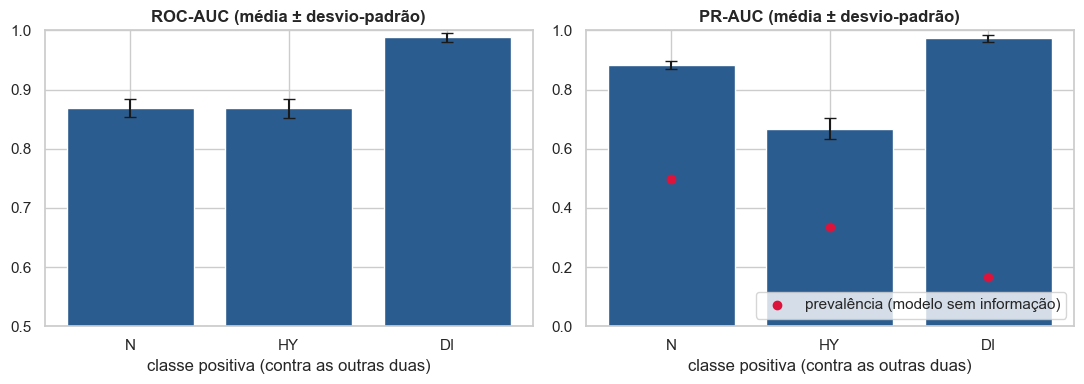

In [5]:
gam_cv = cv_results[cv_results["modelo"] == "GAM"]
mean_gam = gam_cv.groupby("classe")[METRICS].mean().loc[CLASSES]
std_gam = gam_cv.groupby("classe")[METRICS].std().loc[CLASSES]
prevalence = y_train.value_counts(normalize=True).reindex(CLASSES)

table = mean_gam.round(3).astype(str) + " ± " + std_gam.round(3).astype(str)
table.insert(0, "Prevalência", (prevalence * 100).round(1).astype(str) + " %")
table.index = [c + " vs resto" for c in CLASSES]
print("GAM One-vs-Rest, validação cruzada 5x3 (média ± desvio-padrão por partição):")
display(table)

selected_class = mean_gam["ROC-AUC"].idxmax()
print("Hipótese escolhida (maior ROC-AUC médio):", selected_class, "vs resto")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(CLASSES, mean_gam["ROC-AUC"], yerr=std_gam["ROC-AUC"], capsize=4, color="#2b5c8f")
axes[0].set_ylim(0.5, 1.0)
axes[0].set_title("ROC-AUC (média ± desvio-padrão)", fontweight="bold")
axes[1].bar(CLASSES, mean_gam["PR-AUC"], yerr=std_gam["PR-AUC"], capsize=4, color="#2b5c8f")
axes[1].scatter(CLASSES, prevalence.values, color="crimson", zorder=3, label="prevalência (modelo sem informação)")
axes[1].set_ylim(0, 1.0)
axes[1].set_title("PR-AUC (média ± desvio-padrão)", fontweight="bold")
axes[1].legend(loc="lower right")
for ax in axes:
    ax.set_xlabel("classe positiva (contra as outras duas)")
plt.tight_layout()
plt.show()

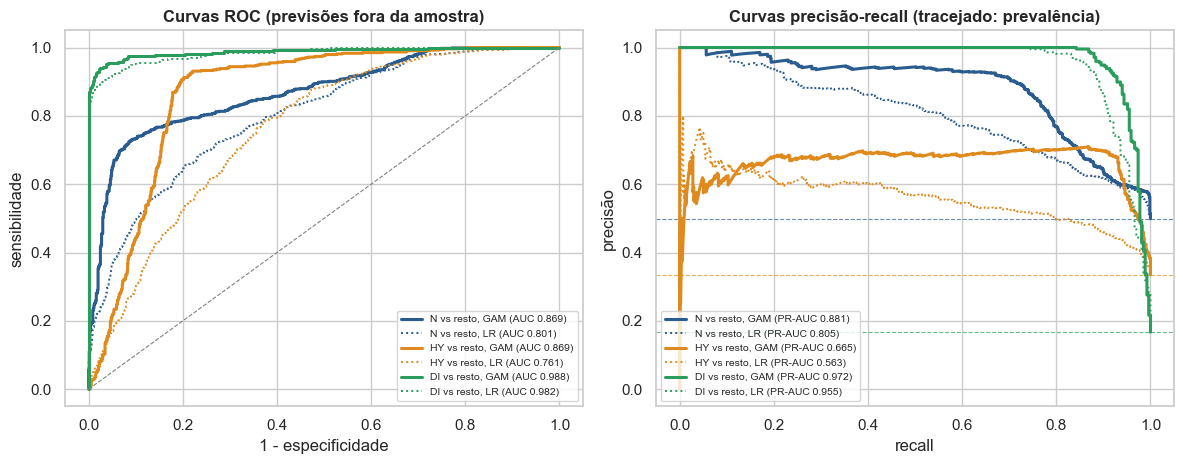

In [6]:
colors = dict(zip(CLASSES, ["#2b5c8f", "#e08a1e", "#2a9d5c"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for cls in CLASSES:
    for model, ls, lw in (("GAM", "-", 2.2), ("LR", ":", 1.4)):
        yt, pr = oof_arrays(cls, model)
        fpr, tpr, _ = roc_curve(yt, pr)
        axes[0].plot(fpr, tpr, ls=ls, lw=lw, color=colors[cls],
                     label=f"{cls} vs resto, {model} (AUC {roc_auc_score(yt, pr):.3f})")
        prec, rec, _ = precision_recall_curve(yt, pr)
        axes[1].plot(rec, prec, ls=ls, lw=lw, color=colors[cls],
                     label=f"{cls} vs resto, {model} (PR-AUC {average_precision_score(yt, pr):.3f})")
    axes[1].axhline(prevalence[cls], color=colors[cls], ls="--", lw=0.8, alpha=0.7)
axes[0].plot([0, 1], [0, 1], color="grey", ls="--", lw=0.8)
axes[0].set_xlabel("1 - especificidade")
axes[0].set_ylabel("sensibilidade")
axes[0].set_title("Curvas ROC (previsões fora da amostra)", fontweight="bold")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precisão")
axes[1].set_title("Curvas precisão-recall (tracejado: prevalência)", fontweight="bold")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=7.5)
plt.tight_layout()
plt.show()



**Leitura.** O critério de escolha é o ROC-AUC médio da validação cruzada, porque não depende do limiar de decisão nem da prevalência da classe e, por isso, permite comparar as três hipóteses entre si. `DI vs resto` é claramente a melhor (0,988), contra 0,869 de `N vs resto` e 0,868 de `HY vs resto`; a diferença é muito maior do que o desvio-padrão entre partições (0,008 a 0,016), enquanto `N` e `HY` não se distinguem. `DI` ganha também em todas as outras métricas (PR-AUC 0,973, F1 0,929, `Balanced accuracy` 0,946, `Log-loss` 0,074).

As curvas ROC e precisão-recall usam previsões fora da amostra (cada observação do treino é prevista por um modelo que não a viu; juntam-se as 5 partições da primeira repetição, por isso os valores diferem ligeiramente das médias por partição da tabela). Mostram a mesma ordem e mostram que o GAM fica claramente acima da regressão logística em `N` e `HY`, enquanto em `DI` as duas curvas quase coincidem junto ao canto superior esquerdo.

A `DI` é a classe menos frequente (16,7%), o que torna a PR-AUC mais exigente: 0,973 está muito acima da linha de base de 0,167, enquanto a PR-AUC de `HY` (0,668) está a apenas o dobro da sua linha de base (0,334). O resultado de `DI` não é, portanto, um efeito de prevalência. Um desempenho tão alto levanta a questão do sobreajuste, tratada na secção 6.4. Um aviso: o Lasso que escolheu os preditores foi ajustado em todo o treino, pelo que a validação cruzada é ligeiramente otimista para os três modelos por igual.


### 6.2 Efeitos estimados no modelo escolhido

O GAM da hipótese escolhida é ajustado em todo o treino. Para cada preditor contínuo mostra-se a **dependência parcial**: a contribuição $f_j(x_j)$ para o logit, com as outras variáveis fixas, e a banda de confiança a 95%. A linha tracejada é a melhor reta através da curva, ou seja, o que um modelo linear assumiria.

Para decidir **se uma curva é mesmo necessária** não basta olhar para o gráfico: com poucos dados qualquer *spline* serpenteia. Por isso, para cada preditor contínuo compara-se, nas mesmas 15 partições da validação cruzada, o GAM completo com o mesmo GAM em que **só esse termo** passa a ser uma reta (`l()`). Se a curva é útil, a `Log-loss` de validação sobe quando se troca a curva pela reta. A diferença é testada com o teste t corrigido (definido acima) e ajustada por Bonferroni, porque se fazem tantos testes quantos preditores contínuos.

O **EDoF** (graus de liberdade efetivos; 1 equivale a uma reta) e a **amplitude** do efeito (máximo menos mínimo da curva entre os percentis 2,5 e 97,5 dos dados, em unidades de logit) descrevem cada curva, mas não servem para decidir sobre a não linearidade, porque dependem do $\lambda$ escolhido. Não se usam os p-values do `pygam`: a própria biblioteca avisa que são demasiado otimistas quando $\lambda$ é estimado.

In [7]:
X_tr_sel = X_train[predictors]
y_tr_sel = (y_train == selected_class).astype(int).values
gam_sel = fit_gam(X_tr_sel, y_tr_sel)
print("lambda escolhido:", float(gam_sel.lam[0][0]))

edof_coef = np.asarray(gam_sel.statistics_["edof_per_coef"])
template = X_train[predictors].mode().iloc[0].values.astype(float)
cont = [col for col in predictors if TERM_TYPES[col] == "s"]

curves, rows = {}, []
for col in cont:
    j = predictors.index(col)
    lo, hi = np.percentile(X_train[col], [2.5, 97.5])
    x = np.linspace(X_train[col].min(), X_train[col].max(), 200)
    grid = np.tile(template, (len(x), 1))
    grid[:, j] = x
    pdep, conf = gam_sel.partial_dependence(term=j, X=grid, width=0.95)
    keep = (x >= lo) & (x <= hi)
    slope, intercept = np.polyfit(x[keep], pdep[keep], 1)
    curves[col] = (x, pdep, conf, slope, intercept)
    rows.append({
        "preditor": col,
        "EDoF": edof_coef[gam_sel.terms.get_coef_indices(j)].sum(),
        "amplitude (log-odds)": np.ptp(pdep[keep]),
    })
effects = pd.DataFrame(rows).set_index("preditor")

lambda escolhido: 0.1


In [8]:
yb_cv = (y_cv == selected_class).astype(int).values
full_ll = (cv_results[(cv_results["classe"] == selected_class) & (cv_results["modelo"] == "GAM")]
           .sort_values("fold")["Log-loss"].values)

ll_linear = {col: [] for col in cont}
for idx_tr, idx_va in cv.split(Xp, y_cv):
    for col in cont:
        g = fit_gam(Xp.iloc[idx_tr], yb_cv[idx_tr], linear=[col])
        ll_linear[col].append(log_loss(yb_cv[idx_va], g.predict_proba(Xp.iloc[idx_va].values)))

rows = []
for col in cont:
    d = np.array(ll_linear[col]) - full_ll
    _, p_val = corrected_ttest(d)
    rows.append({
        "preditor": col,
        "Δ log-loss (reta - curva)": d.mean(),
        "partições em que a curva ajuda (de 15)": int((d > 0).sum()),
        "p (t corrigido)": p_val,
        "p (Bonferroni)": min(1.0, p_val * len(cont)),
    })
ablation = pd.DataFrame(rows).set_index("preditor")
ablation["curva necessária"] = np.where(
    (ablation["p (Bonferroni)"] < 0.05) & (ablation["Δ log-loss (reta - curva)"] > 0), "sim", "não")

effects = effects.join(ablation).sort_values("amplitude (log-odds)", ascending=False)
display(effects.round(4))

,EDoF,amplitude (log-odds),Δ log-loss (reta - curva),partições em que a curva ajuda (de 15),p (t corrigido),p (Bonferroni),curva necessária
preditor,,,,,,,
HbA1c_level,2.2401,39.4309,0.0084,15,0.0000,0.0,sim
age,4.8187,5.3120,0.0007,12,0.8166,1.0,não
blood_pressure,2.7335,3.3086,0.0014,11,0.4312,1.0,não
triglycerides,4.7464,3.0704,0.0017,12,0.3316,1.0,não
alcohol_intake,3.5161,2.8612,0.0041,11,0.1800,1.0,não
homocysteine_level,2.2968,1.6837,0.0054,12,0.3446,1.0,não


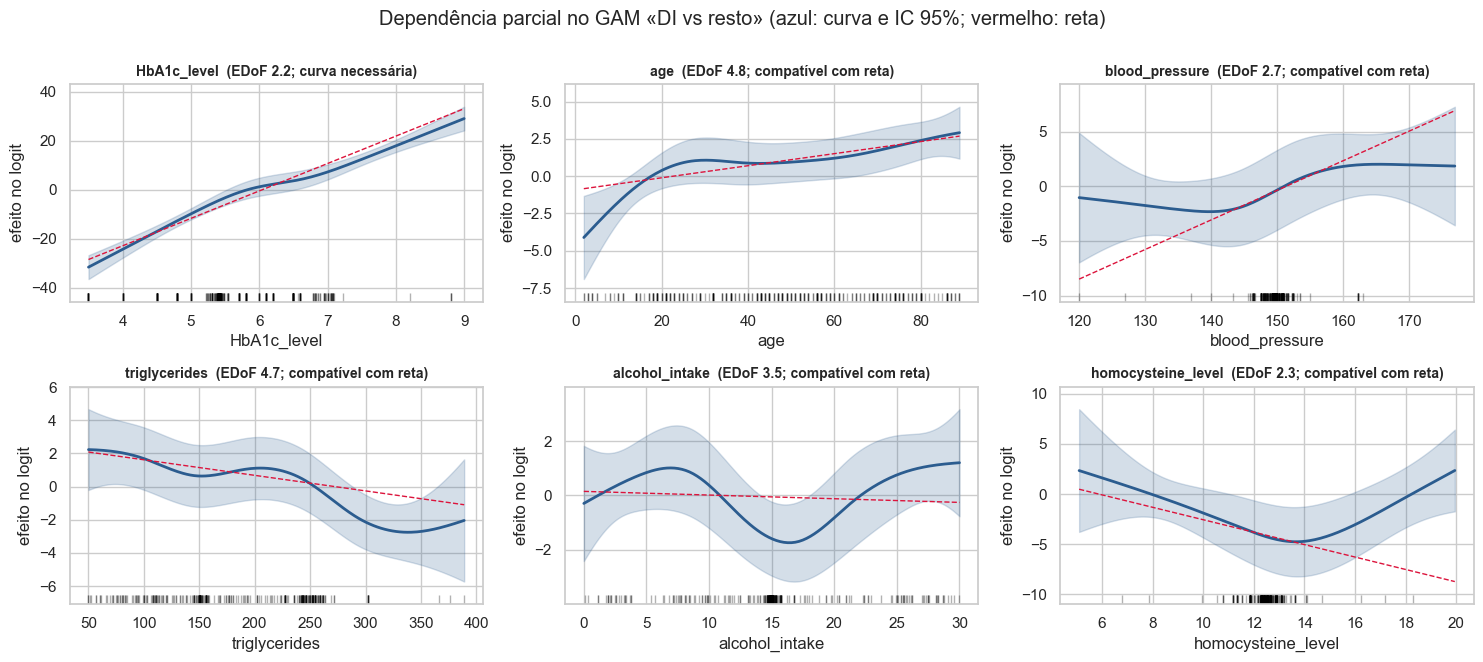

In [9]:
n_cols = 3
n_rows = int(np.ceil(len(cont) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.3 * n_rows))
for ax, col in zip(axes.ravel(), effects.index):
    x, pdep, conf, slope, intercept = curves[col]
    ax.fill_between(x, conf[:, 0], conf[:, 1], color="#2b5c8f", alpha=0.2)
    ax.plot(x, pdep, color="#2b5c8f", lw=2)
    ax.plot(x, slope * x + intercept, color="crimson", ls="--", lw=1)
    sns.rugplot(X_train[col].sample(300, random_state=RANDOM_STATE), ax=ax, color="black", alpha=0.3, height=0.04)
    verdict = "curva necessária" if effects.loc[col, "curva necessária"] == "sim" else "compatível com reta"
    ax.set_title(f"{col}  (EDoF {effects.loc[col, 'EDoF']:.1f}; {verdict})", fontsize=10, fontweight="bold")
    ax.set_ylabel("efeito no logit")
for ax in axes.ravel()[len(cont):]:
    ax.set_visible(False)
fig.suptitle(f"Dependência parcial no GAM «{selected_class} vs resto» (azul: curva e IC 95%; vermelho: reta)", y=1.0)
plt.tight_layout()
plt.show()

In [10]:
rows = []
for j, col in enumerate(predictors):
    if TERM_TYPES[col] == "s":
        continue
    levels = np.sort(X_train[col].unique()).astype(float)
    grid = np.tile(template, (len(levels), 1))
    grid[:, j] = levels
    pdep = gam_sel.partial_dependence(term=j, X=grid)
    effect = pdep - pdep[0]
    rows.append({
        "preditor": col,
        "termo": TERM_TYPES[col],
        "níveis": " / ".join(str(int(v)) for v in levels),
        "efeito no logit (vs nível mais baixo)": " / ".join(f"{e:+.2f}" for e in effect),
        "odds ratio (mais alto vs mais baixo)": float(np.exp(effect[-1])),
        "amplitude": float(np.ptp(effect)),
    })
cat_effects = pd.DataFrame(rows).set_index("preditor").sort_values("amplitude", ascending=False)
display(cat_effects.drop(columns="amplitude").round(3))

,termo,níveis,efeito no logit (vs nível mais baixo),odds ratio (mais alto vs mais baixo)
preditor,,,,
bmi_level,f,1 / 2 / 3 / 4,+0.00 / -2.07 / -1.24 / -0.50,0.605
smoking_Never,l,0 / 1,+0.00 / -1.16,0.312
sugar_consumption,f,1 / 2 / 3,+0.00 / +0.72 / +0.87,2.392
education_level_Primary,l,0 / 1,+0.00 / +0.72,2.057
gender,l,0 / 1,+0.00 / -0.52,0.596
physical_activity,f,1 / 2 / 3,+0.00 / +0.01 / +0.19,1.213
family_history,l,0 / 1,+0.00 / +0.15,1.164
smoking_Current,l,0 / 1,+0.00 / -0.02,0.981
high_ldl_cholesterol,l,0 / 1,+0.00 / -0.02,0.983


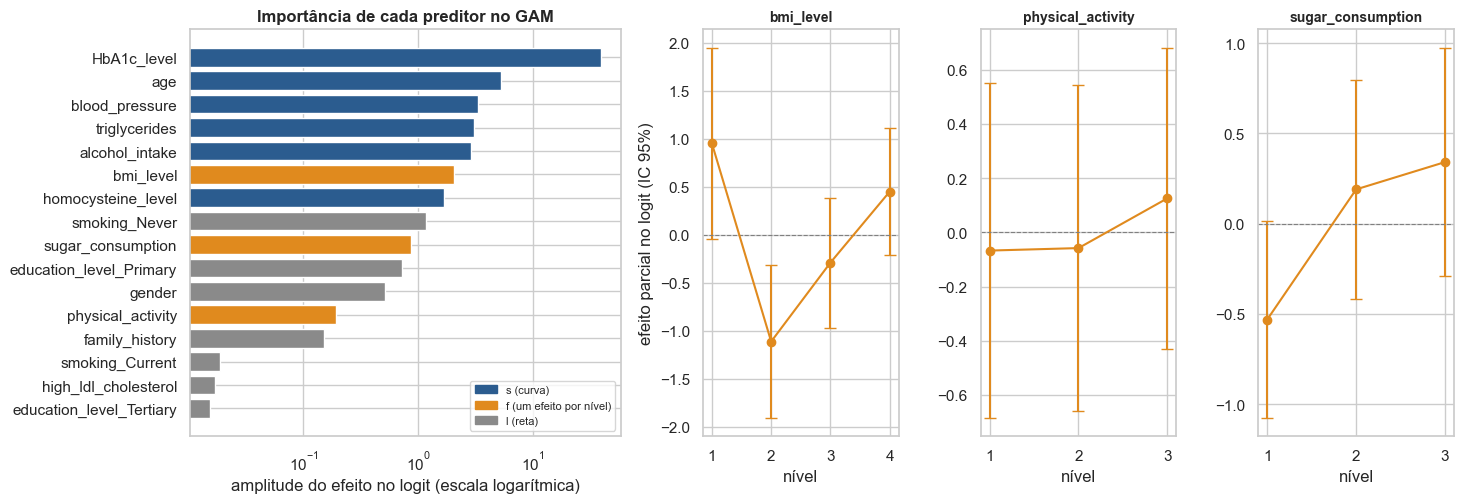

In [11]:
amp = pd.concat([
    effects["amplitude (log-odds)"].to_frame("amplitude").assign(termo="s (curva)"),
    cat_effects[["amplitude"]].assign(termo=cat_effects["termo"].map({"f": "f (um efeito por nível)", "l": "l (reta)"})),
]).sort_values("amplitude")
palette = {"s (curva)": "#2b5c8f", "f (um efeito por nível)": "#e08a1e", "l (reta)": "#8a8a8a"}

f_terms = [col for col in predictors if TERM_TYPES[col] == "f"]
fig, axes = plt.subplots(1, 1 + len(f_terms), figsize=(5.2 + 3.2 * len(f_terms), 5.2),
                         gridspec_kw={"width_ratios": [2.2] + [1] * len(f_terms)})
ax = axes[0]
ax.barh(amp.index, amp["amplitude"], color=[palette[t] for t in amp["termo"]])
ax.set_xscale("log")
ax.set_xlabel("amplitude do efeito no logit (escala logarítmica)")
ax.set_title("Importância de cada preditor no GAM", fontweight="bold")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
ax.legend(handles, palette.keys(), loc="lower right", fontsize=8)

for ax, col in zip(axes[1:], f_terms):
    j = predictors.index(col)
    levels = np.sort(X_train[col].unique()).astype(float)
    grid = np.tile(template, (len(levels), 1))
    grid[:, j] = levels
    pdep, conf = gam_sel.partial_dependence(term=j, X=grid, width=0.95)
    ax.errorbar(levels, pdep, yerr=[pdep - conf[:, 0], conf[:, 1] - pdep], fmt="o-", color="#e08a1e", capsize=4)
    ax.axhline(0, color="grey", lw=0.8, ls="--")
    ax.set_xticks(levels)
    ax.set_title(col, fontsize=10, fontweight="bold")
    ax.set_xlabel("nível")
axes[1].set_ylabel("efeito parcial no logit (IC 95%)")
plt.tight_layout()
plt.show()


**Consistência com a EDA (tarefa 2).** A EDA mediu a associação univariada de cada variável com a classe através do tamanho de efeito de Kruskal-Wallis, $\varepsilon^2 = H/(n-1)$. Repete-se esse cálculo para a hipótese escolhida (classe contra as restantes, nos 2000 registos) e compara-se a ordem das variáveis com a ordem pela amplitude do efeito no GAM, que já é ajustada pelas outras variáveis.

A EDA assinalou ainda uma forte concentração de valores em torno da mediana (secção 3.2). A última tabela verifica se isso interfere com as curvas: conta as linhas que têm exatamente o valor mais frequente de cada variável e quantas pertencem à classe escolhida.

In [12]:
mask = (y.values == selected_class)
eps = {}
for col in cont:
    H, _ = stats.kruskal(df.loc[mask, col], df.loc[~mask, col])
    eps[col] = H / (len(df) - 1)

compare = effects[["amplitude (log-odds)", "curva necessária"]].copy()
compare["ε² (EDA, classe vs resto)"] = pd.Series(eps)
compare["ordem GAM"] = compare["amplitude (log-odds)"].rank(ascending=False).astype(int)
compare["ordem EDA"] = compare["ε² (EDA, classe vs resto)"].rank(ascending=False).astype(int)
display(compare.round(3))

rho, p_rho = stats.spearmanr(compare["amplitude (log-odds)"], compare["ε² (EDA, classe vs resto)"])
print(f"Correlação de Spearman entre as duas ordens: rho = {rho:.2f} (p = {p_rho:.3f})")

top3 = list(effects.index[:3])
print("\nMedianas por classe das 3 variáveis com maior efeito no GAM (dados completos):")
display(df.groupby("target_class")[top3].median().loc[CLASSES].round(2))

rows = []
for col in cont:
    value = df[col].mode().iloc[0]
    at_value = (df[col] == value).values
    rows.append({
        "preditor": col,
        "valor mais frequente": value,
        "linhas com esse valor": int(at_value.sum()),
        f"dessas, da classe {selected_class}": int((at_value & mask).sum()),
        f"esperado se fosse independente": at_value.sum() * mask.mean(),
    })
print("\nLinhas no valor mais frequente de cada variável:")
display(pd.DataFrame(rows).set_index("preditor").round(1))

,amplitude (log-odds),curva necessária,"ε² (EDA, classe vs resto)",ordem GAM,ordem EDA
preditor,,,,,
HbA1c_level,39.431,sim,0.386,1,1
age,5.312,não,0.025,2,3
blood_pressure,3.309,não,0.034,3,2
triglycerides,3.070,não,0.015,4,4
alcohol_intake,2.861,não,0.002,5,6
homocysteine_level,1.684,não,0.007,6,5


Correlação de Spearman entre as duas ordens: rho = 0.89 (p = 0.019)

Medianas por classe das 3 variáveis com maior efeito no GAM (dados completos):


,HbA1c_level,age,blood_pressure
target_class,,,
N,5.41,42.0,149.59
HY,5.40,54.0,149.51
DI,6.95,58.0,149.97



Linhas no valor mais frequente de cada variável:


,valor mais frequente,linhas com esse valor,"dessas, da classe DI",esperado se fosse independente
preditor,,,,
age,80.0,66,14,11.0
HbA1c_level,6.5,90,3,15.0
triglycerides,251.3,44,0,7.3
blood_pressure,149.5,88,0,14.7
homocysteine_level,12.5,88,0,14.7
alcohol_intake,15.0,45,0,7.5


**Onde está, então, a não linearidade?** O teste por termo acima tem pouca potência (cada curva sozinha acrescenta pouco e a correção de Bonferroni é exigente), mas os gráficos mostram um padrão repetido: em várias variáveis a curva tem forma de **U com o mínimo no centro**, o que uma reta não consegue representar. Um U assim significa que a probabilidade da classe sobe quando o valor se afasta do centro nos dois sentidos, ou seja, que a classe tem a **mesma média mas maior dispersão**.

Verifica-se diretamente, no treino, com o teste de Welch (diferença de médias) e o teste de Levene centrado na mediana (diferença de dispersão, com Bonferroni). Depois mede-se, na mesma validação cruzada, se um termo quadrático $(x - \text{mediana})^2$ numa regressão logística chega para recuperar o que o GAM ganha, e o que acontece ao GAM quando só essas variáveis, ou só as restantes, mantêm a curva. A seleção das variáveis usa o treino inteiro (tal como o Lasso), pelo que a validação cruzada fica ligeiramente otimista.

In [13]:
mask_tr = (y_train == selected_class).values
rows = []
for col in cont:
    a, b = X_train.loc[mask_tr, col], X_train.loc[~mask_tr, col]
    rows.append({
        "preditor": col,
        f"média ({selected_class})": a.mean(),
        "média (resto)": b.mean(),
        f"desvio-padrão ({selected_class})": a.std(),
        "desvio-padrão (resto)": b.std(),
        "p média (Welch)": stats.ttest_ind(a, b, equal_var=False).pvalue,
        "p dispersão (Levene)": stats.levene(a, b).pvalue,
    })
disp = pd.DataFrame(rows).set_index("preditor")
disp["p dispersão (Bonferroni)"] = np.minimum(1.0, disp["p dispersão (Levene)"] * len(cont))
disp["só dispersão"] = np.where(
    (disp["p dispersão (Bonferroni)"] < 0.05) & (disp["p média (Welch)"] > 0.05), "sim", "não")
display(disp.round(4))

u_vars = disp.index[disp["só dispersão"] == "sim"].tolist()
print("Mesma média, dispersão diferente:", u_vars)

Xq = Xp.copy()
for col in u_vars:
    Xq[f"{col}²"] = (Xp[col] - X_train[col].median()) ** 2

ll_lr = (cv_results[(cv_results["classe"] == selected_class) & (cv_results["modelo"] == "LR")]
         .sort_values("fold")["Log-loss"].values)
other_vars = [col for col in cont if col not in u_vars]
ll_lrq, ll_only_u, ll_only_other, ll_all_lin = [], [], [], []
for idx_tr, idx_va in cv.split(Xp, y_cv):
    m = make_lr().fit(Xq.iloc[idx_tr], yb_cv[idx_tr])
    ll_lrq.append(log_loss(yb_cv[idx_va], m.predict_proba(Xq.iloc[idx_va])[:, 1]))
    for store, linear in [(ll_only_u, other_vars), (ll_only_other, u_vars), (ll_all_lin, cont)]:
        g = fit_gam(Xp.iloc[idx_tr], yb_cv[idx_tr], linear=linear)
        store.append(log_loss(yb_cv[idx_va], g.predict_proba(Xp.iloc[idx_va].values)))
ll_lrq, ll_only_u, ll_only_other, ll_all_lin = map(np.array, (ll_lrq, ll_only_u, ll_only_other, ll_all_lin))

print("Log-loss médio na validação cruzada (mais baixo é melhor):")
display(pd.Series({
    "LR": ll_lr.mean(),
    "LR + termos quadráticos nessas variáveis": ll_lrq.mean(),
    "GAM todo em reta (GAM linear)": ll_all_lin.mean(),
    "GAM com curva só nessas variáveis": ll_only_u.mean(),
    "GAM com curva só nas restantes": ll_only_other.mean(),
    "GAM completo": full_ll.mean(),
}, name="Log-loss").round(4).to_frame())

rows = []
for label, d in [
    ("GAM completo contra GAM todo em reta", ll_all_lin - full_ll),
    ("GAM completo contra GAM com curva só nessas variáveis", ll_only_u - full_ll),
    ("GAM completo contra GAM com curva só nas restantes", ll_only_other - full_ll),
    ("LR + quadráticos contra LR", ll_lr - ll_lrq),
    ("GAM completo contra LR + quadráticos", ll_lrq - full_ll),
]:
    _, p_val = corrected_ttest(d)
    rows.append({"comparação (primeiro modelo mais flexível)": label,
                 "Δ log-loss a favor do mais flexível": d.mean(),
                 "partições em que ganha (de 15)": int((d > 0).sum()),
                 "p (t corrigido)": p_val})
display(pd.DataFrame(rows).set_index("comparação (primeiro modelo mais flexível)").round(4))

,média (DI),média (resto),desvio-padrão (DI),desvio-padrão (resto),p média (Welch),p dispersão (Levene),p dispersão (Bonferroni),só dispersão
preditor,,,,,,,,
age,56.2697,46.5851,19.6754,22.4107,0.0000,0.0023,0.0138,não
HbA1c_level,6.9770,5.3812,0.5660,0.6856,0.0000,0.0001,0.0005,não
triglycerides,167.0239,185.8478,64.0808,66.9305,0.0000,0.0053,0.0316,não
blood_pressure,150.6220,149.5231,4.5672,3.2440,0.0002,0.0001,0.0007,não
homocysteine_level,12.5150,12.5179,1.1963,0.8851,0.9706,0.3396,1.0000,não
alcohol_intake,14.4615,14.8803,7.5777,6.0165,0.3954,0.0000,0.0000,sim


Mesma média, dispersão diferente: ['alcohol_intake']


Log-loss médio na validação cruzada (mais baixo é melhor):


,Log-loss
LR,0.1034
LR + termos quadráticos nessas variáveis,0.0975
GAM todo em reta (GAM linear),0.1023
GAM com curva só nessas variáveis,0.0934
GAM com curva só nas restantes,0.0776
GAM completo,0.0735


,Δ log-loss a favor do mais flexível,partições em que ganha (de 15),p (t corrigido)
comparação (primeiro modelo mais flexível),,,
GAM completo contra GAM todo em reta,0.0288,15,0.0013
GAM completo contra GAM com curva só nessas variáveis,0.0199,15,0.0020
GAM completo contra GAM com curva só nas restantes,0.0041,11,0.1800
LR + quadráticos contra LR,0.0059,14,0.0019
GAM completo contra LR + quadráticos,0.0240,14,0.0050



**Leitura.**

*Que variáveis contam.* O efeito de `HbA1c_level` domina tudo: a sua curva percorre cerca de 39 unidades de logit entre os percentis 2,5 e 97,5, contra 5,3 de `age`, 3,3 de `blood_pressure`, 3,1 de `triglycerides`, 2,9 de `alcohol_intake` e 1,7 de `homocysteine_level` (o gráfico de barras usa escala logarítmica). Uma amplitude desta ordem é sinal de quase separação, ou seja, a `HbA1c` quase decide sozinha se um doente é `DI` (medianas de 6,95 em `DI` contra 5,40 e 5,41 em `HY` e `N`; $\varepsilon^2 = 0{,}386$ na EDA). A curva é quase uma reta (EDoF 2,2). O teste de ablação diz que a curva é estatisticamente necessária (trocá-la por uma reta aumenta a `Log-loss` em 0,008, nas 15 partições), mas o desvio é pequeno face à escala: a curva afasta-se da reta só entre cerca de 6 e 7,2. `age` e `blood_pressure` têm efeito crescente e `triglycerides` decrescente (média de 167 em `DI` contra 186 nas outras classes), todos compatíveis com retas dentro da banda de confiança; em `age` a banda é muito larga abaixo dos 15 anos, onde há poucos dados.

Entre as variáveis categóricas (gráficos à direita e tabela acima) os efeitos são bem menores, e as bandas de confiança são largas. Os maiores são `smoking_Never` (odds ratio 0,31), `gender` (0,60), `sugar_consumption` (2,39 do nível 1 ao 3) e `education_level_Primary` (2,06); `smoking_Current`, `high_ldl_cholesterol` e `education_level_Tertiary` têm odds ratio próximo de 1. O único padrão não monótono é o de `bmi_level`: o nível 2 tem cerca de 2 unidades de logit a menos do que o 1, e o nível 4 volta a subir.

*Que variáveis têm efeito não linear.* Pelo teste de ablação por termo, só `HbA1c_level`, e de forma ligeira. Nas outras cinco depois da correção de Bonferroni todos os p-values são 1, e o ganho de cada curva sozinha é pequeno (no máximo 0,005 de `Log-loss`). Mas esse teste tem pouca potência para efeitos pequenos, e o gráfico mostra uma forma de U em `alcohol_intake` e em `homocysteine_level`. Em `alcohol_intake` a tabela de dispersão dá a explicação: `DI` tem **a mesma média** (14,5 contra 14,9; Welch p = 0,40) mas **maior desvio-padrão** (7,6 contra 6,0; Levene com Bonferroni abaixo de 0,001), e é a única variável que cumpre este critério; um U é a forma de dizer «a probabilidade de `DI` sobe quando se está longe do centro». Em `homocysteine_level` não há diferença de dispersão (Levene p = 0,34) e a banda de confiança é larga, pelo que o U não é de confiar.

Para medir o que vale a não linearidade no conjunto, comparou-se a `Log-loss` de validação cruzada de vários modelos. O GAM todo em reta tem 0,1023 e o GAM completo 0,0735 (melhor nas 15 partições; p = 0,0013). Com curvas só em `alcohol_intake` fica em 0,0934; com curvas só nas outras cinco variáveis fica em 0,0776, ou seja, essas cinco dão cerca de 86% do ganho (0,0247 em 0,0288). Uma regressão logística com um termo quadrático em `alcohol_intake` desce de 0,1034 para 0,0975 (p = 0,002), isto é, recupera só cerca de 20% do ganho total do GAM sobre a regressão logística (0,0299). A não linearidade está, portanto, repartida por várias variáveis (nas ablações individuais, sobretudo `HbA1c_level`, `homocysteine_level` e `alcohol_intake`) e nenhum termo isolado a explica.

*Consistência com a EDA.* A `HbA1c` é a primeira variável tanto na EDA como no GAM, e a correlação de Spearman entre as duas ordenações das seis contínuas é 0,89 (p = 0,019). As diferenças são trocas de lugares vizinhos (`age` e `blood_pressure` em 2.º e 3.º; `alcohol_intake` e `homocysteine_level` em 5.º e 6.º), todas com $\varepsilon^2$ pequeno (no máximo 0,034) fora da `HbA1c`. Também a forte concentração de valores no centro assinalada na EDA (secção 3.2) reaparece aqui: nas linhas que têm exatamente o valor mais frequente de cada variável (exceto `age`) há muito menos `DI` do que o esperado (por exemplo, 0 em 88 linhas de `blood_pressure`, para 14,7 esperadas; 3 em 90 em `HbA1c_level`, para 15 esperadas). A origem dessa repetição (possivelmente imputação pela mediana) deve ser confirmada.

*Limitações.* Os intervalos de confiança do `pygam` e os seus p-values são aproximados (a própria biblioteca avisa), por isso não se usaram p-values do GAM; e a quase separação em `HbA1c` faz com que algumas iterações emitam avisos numéricos, que foram silenciados.


### 6.3 GAM contra regressão logística linear

O mesmo problema binário (hipótese escolhida), os mesmos preditores e as mesmas 15 partições da validação cruzada. A regressão logística usa as variáveis padronizadas (`StandardScaler`) e `C = 1`.

Há uma diferença entre os dois modelos que não é flexibilidade: o GAM escolhe $\lambda$ por `gridsearch` e a regressão logística tem uma regularização fixa. Para separar as duas coisas junta-se um terceiro modelo, o **GAM linear**: o mesmo GAM, mas com todos os preditores contínuos em `l()`. A comparação GAM contra GAM linear mede só o que as curvas acrescentam.

As diferenças usam o teste t corrigido de Nadeau e Bengio, que tem em conta que as partições partilham observações (o teste t simples sobre as 15 partições daria p-values demasiado baixos). Na `Log-loss` valores mais baixos são melhores.

DI vs resto, GAM contra regressão logística (validação cruzada 5x3, mesmas partições):


,GAM,LR,diferença,partições em que GAM é melhor (de 15),p (t corrigido)
métrica,,,,,
ROC-AUC,0.9885,0.9819,0.0066,15,0.0528
PR-AUC,0.9730,0.9545,0.0185,15,0.0051
Balanced accuracy,0.9462,0.9285,0.0177,14,0.0480
F1,0.9285,0.9007,0.0278,13,0.0621
Recall,0.9002,0.8689,0.0312,12,0.0665
Precision,0.9601,0.9377,0.0224,13,0.3065
Log-loss,0.0735,0.1034,-0.0299,15,0.0016


GAM contra GAM linear (só as curvas):


,GAM,GAM linear,diferença,partições em que GAM é melhor (de 15),p (t corrigido)
métrica,,,,,
ROC-AUC,0.9885,0.9830,0.0055,14,0.0490
PR-AUC,0.9730,0.9562,0.0168,15,0.0050
Balanced accuracy,0.9462,0.9341,0.0121,11,0.1643
F1,0.9285,0.9030,0.0255,11,0.0610
Recall,0.9002,0.8827,0.0175,8,0.2836
Precision,0.9601,0.9270,0.0330,11,0.0609
Log-loss,0.0735,0.1023,-0.0288,15,0.0013


ROC-AUC médio nas três hipóteses (GAM contra LR):


modelo,GAM,LR,GAM - LR
classe,,,
N,0.8687,0.8012,0.0675
HY,0.8680,0.7606,0.1074
DI,0.9885,0.9819,0.0066


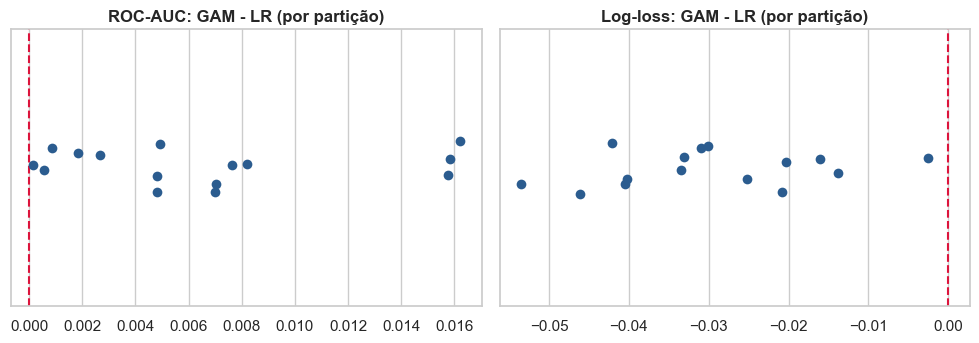

In [14]:
rows = []
for fold, (idx_tr, idx_va) in enumerate(cv.split(Xp, y_cv)):
    g = fit_gam(Xp.iloc[idx_tr], yb_cv[idx_tr], linear=cont)
    rows.append({"fold": fold, "classe": selected_class, "modelo": "GAM linear",
                 **binary_metrics(yb_cv[idx_va], g.predict_proba(Xp.iloc[idx_va].values))})
sel_cv = pd.concat([cv_results[cv_results["classe"] == selected_class], pd.DataFrame(rows)], ignore_index=True)

LOWER_IS_BETTER = {"Log-loss"}
n_folds = sel_cv["fold"].nunique()


def paired_table(model_a, model_b):
    wide = sel_cv.pivot_table(index="fold", columns="modelo", values=METRICS)
    rows = []
    for m in METRICS:
        d = (wide[(m, model_a)] - wide[(m, model_b)]).values
        _, p_val = corrected_ttest(d)
        a_better = (d < 0) if m in LOWER_IS_BETTER else (d > 0)
        rows.append({
            "métrica": m,
            model_a: wide[(m, model_a)].mean(),
            model_b: wide[(m, model_b)].mean(),
            "diferença": d.mean(),
            f"partições em que {model_a} é melhor (de {n_folds})": int(a_better.sum()),
            "p (t corrigido)": p_val,
        })
    return pd.DataFrame(rows).set_index("métrica")


print(f"{selected_class} vs resto, GAM contra regressão logística (validação cruzada 5x3, mesmas partições):")
display(paired_table("GAM", "LR").round(4))
print("GAM contra GAM linear (só as curvas):")
display(paired_table("GAM", "GAM linear").round(4))

print("ROC-AUC médio nas três hipóteses (GAM contra LR):")
auc_all = cv_results.pivot_table(index="classe", columns="modelo", values="ROC-AUC").loc[CLASSES]
auc_all["GAM - LR"] = auc_all["GAM"] - auc_all["LR"]
display(auc_all.round(4))

wide = sel_cv.pivot_table(index="fold", columns="modelo", values=["ROC-AUC", "Log-loss"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, m in zip(axes, ["ROC-AUC", "Log-loss"]):
    sns.stripplot(x=(wide[(m, "GAM")] - wide[(m, "LR")]).values, ax=ax, color="#2b5c8f", size=7)
    ax.axvline(0, color="crimson", ls="--")
    ax.set_title(f"{m}: GAM - LR (por partição)", fontweight="bold")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Conjunto de teste (hold-out, 400 observações, 66 da classe DI):


,ROC-AUC,PR-AUC,Balanced accuracy,F1,Recall,Precision,Log-loss
GAM,0.9837,0.9701,0.9440,0.9291,0.8939,0.9672,0.0813
GAM linear,0.9793,0.9530,0.9365,0.8939,0.8939,0.8939,0.1079
LR,0.9782,0.9484,0.9380,0.9008,0.8939,0.9077,0.1116


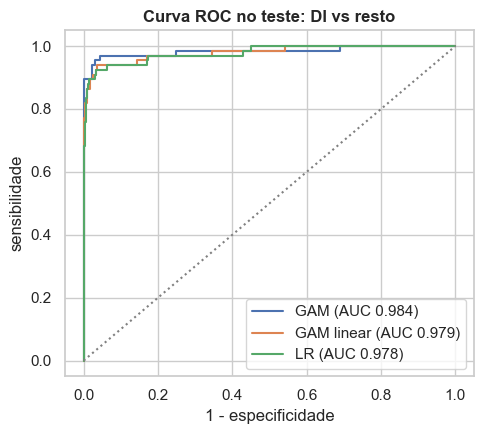

In [15]:
X_te_sel = X_test[predictors]
y_te_sel = (y_test == selected_class).astype(int).values
lr_sel = make_lr().fit(X_tr_sel, y_tr_sel)
gam_lin = fit_gam(X_tr_sel, y_tr_sel, linear=cont)
proba_test = {
    "GAM": gam_sel.predict_proba(X_te_sel.values),
    "GAM linear": gam_lin.predict_proba(X_te_sel.values),
    "LR": lr_sel.predict_proba(X_te_sel)[:, 1],
}
test_table = pd.DataFrame({name: binary_metrics(y_te_sel, p) for name, p in proba_test.items()}).T
print(f"Conjunto de teste (hold-out, {len(y_te_sel)} observações, {y_te_sel.sum()} da classe {selected_class}):")
display(test_table.round(4))

fig, ax = plt.subplots(figsize=(5, 4.5))
for name, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_te_sel, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_te_sel, p):.3f})")
ax.plot([0, 1], [0, 1], color="grey", ls=":")
ax.set_xlabel("1 - especificidade")
ax.set_ylabel("sensibilidade")
ax.set_title(f"Curva ROC no teste: {selected_class} vs resto", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

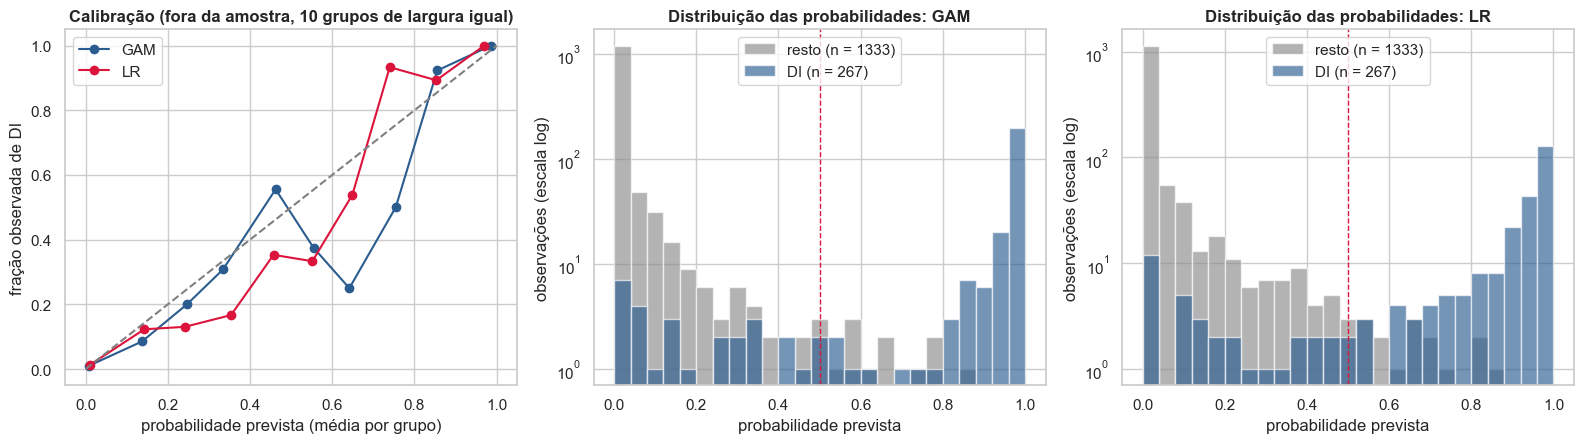

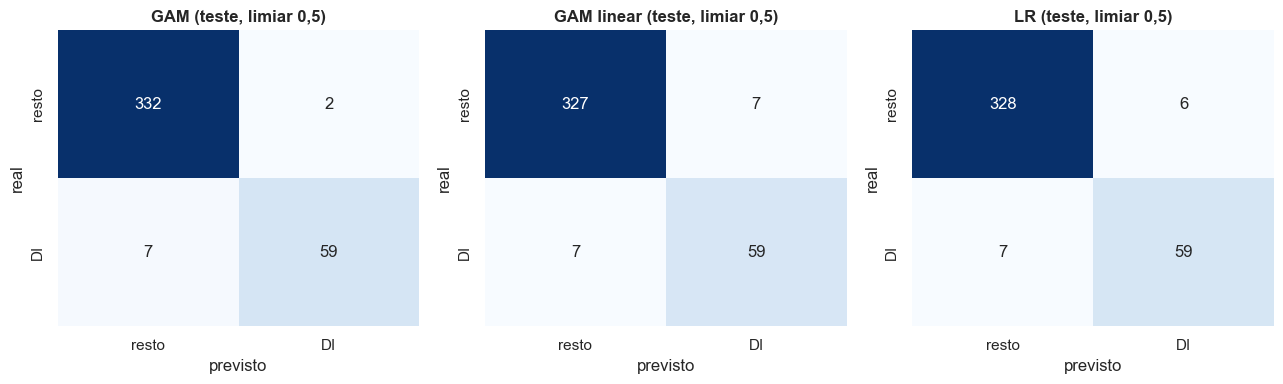

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for model, color in (("GAM", "#2b5c8f"), ("LR", "crimson")):
    yt, pr = oof_arrays(selected_class, model)
    frac_pos, mean_pred = calibration_curve(yt, pr, n_bins=10, strategy="uniform")
    axes[0].plot(mean_pred, frac_pos, "o-", color=color, label=model)
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set_xlabel("probabilidade prevista (média por grupo)")
axes[0].set_ylabel(f"fração observada de {selected_class}")
axes[0].set_title("Calibração (fora da amostra, 10 grupos de largura igual)", fontweight="bold")
axes[0].legend()

for ax, model in zip(axes[1:], ("GAM", "LR")):
    yt, pr = oof_arrays(selected_class, model)
    bins = np.linspace(0, 1, 26)
    ax.hist(pr[yt == 0], bins=bins, alpha=0.65, color="#8a8a8a", label=f"resto (n = {(yt == 0).sum()})")
    ax.hist(pr[yt == 1], bins=bins, alpha=0.65, color="#2b5c8f", label=f"{selected_class} (n = {(yt == 1).sum()})")
    ax.axvline(0.5, color="crimson", ls="--", lw=1)
    ax.set_yscale("log")
    ax.set_xlabel("probabilidade prevista")
    ax.set_ylabel("observações (escala log)")
    ax.set_title(f"Distribuição das probabilidades: {model}", fontweight="bold")
    ax.legend(loc="upper center")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, p) in zip(axes, proba_test.items()):
    cm = confusion_matrix(y_te_sel, (p >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["resto", selected_class], yticklabels=["resto", selected_class])
    ax.set_title(f"{name} (teste, limiar 0,5)", fontweight="bold")
    ax.set_xlabel("previsto")
    ax.set_ylabel("real")
plt.tight_layout()
plt.show()



**Leitura.**

*Na hipótese escolhida (`DI vs resto`) o GAM melhora sobretudo a qualidade das probabilidades e, só ligeiramente, a discriminação.* A `Log-loss` desce de 0,1034 (regressão logística) para 0,0735, com o GAM melhor em todas as 15 partições (p = 0,0016). Como se testam 7 métricas, o limiar de Bonferroni é 0,007: passam a `Log-loss` e a PR-AUC (0,973 contra 0,955; p = 0,005). O ROC-AUC sobe de 0,982 para 0,989, com o GAM melhor nas 15 partições mas sem chegar a p < 0,05 (p = 0,053); `Balanced accuracy` (p = 0,048), F1 (p = 0,062) e recall (p = 0,067) apontam no mesmo sentido, sem folga, e a precisão não se distingue (p = 0,31). Em termos práticos, a regressão logística já ordena os doentes quase tão bem como o GAM; o GAM atribui probabilidades melhores. Os gráficos de calibração e dos histogramas das probabilidades (fora da amostra) mostram que os dois modelos seguem a diagonal nos extremos, onde estão quase todas as observações; na zona intermédia há poucos casos e os pontos oscilam, sem diferença clara entre os dois. Os histogramas mostram que o GAM é mais decidido: deixa mais `DI` com probabilidade próxima de 1.

*De onde vem o ganho.* O GAM linear (mesmo modelo, todas as curvas substituídas por retas) tem `Log-loss` 0,1023, praticamente igual à da regressão logística (0,1034), pelo que a diferença não se deve à regularização. A diferença entre o GAM completo e o GAM linear (0,0288; p = 0,0013) é o que as curvas acrescentam e, como se viu em 6.2, está repartida por várias variáveis; um termo quadrático em `alcohol_intake` recupera só cerca de 20% do ganho.

*No conjunto de teste* (400 observações, 66 de `DI`) o quadro é o mesmo: ROC-AUC 0,984 (GAM), 0,979 (GAM linear) e 0,978 (regressão logística), `Log-loss` 0,081 contra 0,108 e 0,112. Os três modelos encontram 59 dos 66 `DI`; o GAM comete 2 falsos positivos, contra 7 (GAM linear) e 6 (regressão logística), uma diferença pequena em contagens para tirar conclusões.

*Nas outras hipóteses a história é outra.* Para `N vs resto` e `HY vs resto` o GAM é muito melhor do que a regressão logística (ROC-AUC 0,869 contra 0,801 e 0,868 contra 0,761), o que indica efeitos não lineares, ou interações, que um modelo linear não apanha. Estas hipóteses não foram analisadas em detalhe, porque o enunciado pede só a escolhida.

*Conclusão crítica.* Para `DI vs resto` uma regressão logística simples já discrimina muito bem; o GAM acrescenta um ganho moderado e consistente, sobretudo nas probabilidades. O custo é uma interpretação menos direta (curvas em vez de um coeficiente), a sensibilidade à escolha de $\lambda$ e o risco de sobreajuste, que se verifica na secção seguinte. As conclusões têm ainda duas ressalvas: os preditores foram escolhidos com o treino todo (comparação equilibrada entre modelos, mas otimista em valor absoluto) e a diferença entre partições é estimada com o teste t corrigido, que é só uma aproximação.


### 6.4 Controlo de sobreajuste

O professor chamou a atenção para o risco de sobreajuste do GAM: um modelo flexível pode acertar quase tudo no treino e falhar em dados novos, e um desempenho muito alto deve ser examinado. A indicação foi dada oralmente e o enunciado não fixa um valor, por isso o critério usado aqui é definido de forma explícita:

**a perda relativa de desempenho do treino para a validação (e para o teste) deve ser inferior a 10%**, isto é, $(\text{treino} - \text{validação}) / \text{treino} < 10\%$, medida no `ROC-AUC`, na `Balanced accuracy` e no `F1`. A `Log-loss` fica de fora porque, sendo uma perda, é mais baixa no treino e uma «perda relativa» não faz sentido; é mostrada à parte.

A verificação tem quatro partes: (1) a perda treino-validação-teste nas três hipóteses; (2) o efeito do parâmetro $\lambda$; (3) a curva de aprendizagem; (4) controlos: etiquetas baralhadas e um modelo só com a `HbA1c`. As partes 2 a 4 usam a hipótese escolhida. Os valores de treino são as médias dos 15 ajustes da validação cruzada, avaliados nos dados com que cada um foi treinado.

treino  validação cruzada  teste  \
hipótese    modelo métrica                                               
DI vs resto GAM    ROC-AUC             0.993              0.988  0.984   
                   Balanced accuracy   0.960              0.946  0.944   
                   F1                  0.952              0.929  0.929   
            LR     ROC-AUC             0.988              0.982  0.978   
                   Balanced accuracy   0.936              0.928  0.938   
                   F1                  0.914              0.901  0.901   
HY vs resto GAM    ROC-AUC             0.895              0.868  0.890   
                   Balanced accuracy   0.847              0.821  0.850   
                   F1                  0.786              0.754  0.793   
            LR     ROC-AUC             0.773              0.761  0.760   
                   Balanced accuracy   0.650              0.641  0.651   
                   F1                  0.511              0.497  0.515   
N vs resto  GAM    ROC-AUC             0.892              0.869  0.877   
                   Balanced accuracy   0.824              0.803  0.818   
                   F1                  0.817              0.797  0.815   
            LR     ROC-AUC             0.811              0.801  0.786   
                   Balanced accuracy   0.729              0.719  0.738   
                   F1                  0.727              0.717  0.733   

                                      perda treino→validação (%)  \
hipótese    modelo métrica                                         
DI vs resto GAM    ROC-AUC                                 0.486   
                   Balanced accuracy                       1.412   
                   F1                                      2.423   
            LR     ROC-AUC                                 0.577   
                   Balanced accuracy                       0.776   
                   F1                                      1.449   
HY vs resto GAM    ROC-AUC                                 3.025   
                   Balanced accuracy                       3.119   
                   F1                                      4.041   
            LR     ROC-AUC                                 1.598   
                   Balanced accuracy                       1.483   
                   F1                                      2.702   
N vs resto  GAM    ROC-AUC                                 2.593   
                   Balanced accuracy                       2.512   
                   F1                                      2.414   
            LR     ROC-AUC                                 1.161   
                   Balanced accuracy                       1.322   
                   F1                                      1.430   

                                      perda treino→teste (%)  
hipótese    modelo métrica                                    
DI vs resto GAM    ROC-AUC                             0.967  
                   Balanced accuracy                   1.646  
                   F1                                  2.357  
            LR     ROC-AUC                             0.953  
                   Balanced accuracy                  -0.241  
                   F1                                  1.447  
HY vs resto GAM    ROC-AUC                             0.560  
                   Balanced accuracy                  -0.336  
                   F1                                 -0.861  
            LR     ROC-AUC                             1.677  
                   Balanced accuracy                  -0.023  
                   F1                                 -0.750  
N vs resto  GAM    ROC-AUC                             1.651  
                   Balanced accuracy                   0.760  
                   F1                                  0.209  
            LR     ROC-AUC                             3.041  
                   Balanced accuracy                  -1.195  

Maior perda treino→validação nos GAM: 4.0% (limite: 10%)

Complexidade efetiva do GAM (média das 15 partições; cada partição treina com 1280 observações):


,lambda_mediano,EDoF_medio,EDoF / observações de treino
classe,,,
N,0.1,44.483,0.035
HY,0.1,43.608,0.034
DI,0.1,33.229,0.026


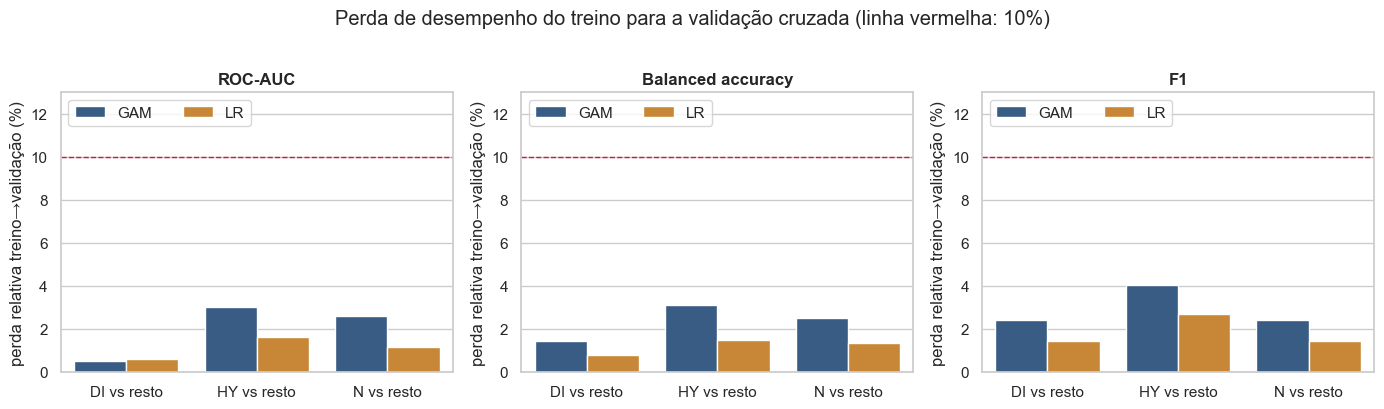

In [17]:
GAP_METRICS = ["ROC-AUC", "Balanced accuracy", "F1"]
LIMIT = 10  # percentagem: perda relativa máxima aceite entre treino e validação

mean_train = cv_train.groupby(["classe", "modelo"])[METRICS].mean()
mean_val = cv_results.groupby(["classe", "modelo"])[METRICS].mean()

test_rows = []
for cls in CLASSES:
    yb_tr = (y_train == cls).astype(int).values
    yb_te = (y_test == cls).astype(int).values
    g = gam_sel if cls == selected_class else fit_gam(X_tr_sel, yb_tr)
    lr_c = lr_sel if cls == selected_class else make_lr().fit(X_tr_sel, yb_tr)
    for name, proba in (("GAM", g.predict_proba(X_te_sel.values)), ("LR", lr_c.predict_proba(X_te_sel)[:, 1])):
        test_rows.append({"classe": cls, "modelo": name, **binary_metrics(yb_te, proba)})
mean_test = pd.DataFrame(test_rows).set_index(["classe", "modelo"])[METRICS]

rows = []
for (cls, model) in mean_val.index:
    for m in GAP_METRICS:
        tr, va, te = mean_train.loc[(cls, model), m], mean_val.loc[(cls, model), m], mean_test.loc[(cls, model), m]
        rows.append({"hipótese": f"{cls} vs resto", "modelo": model, "métrica": m,
                     "treino": tr, "validação cruzada": va, "teste": te,
                     "perda treino→validação (%)": 100 * (tr - va) / tr,
                     "perda treino→teste (%)": 100 * (tr - te) / tr})
gaps = pd.DataFrame(rows)
display(gaps.set_index(["hipótese", "modelo", "métrica"]).round(3))

worst = gaps.loc[gaps["modelo"] == "GAM", "perda treino→validação (%)"].max()
print(f"Maior perda treino→validação nos GAM: {worst:.1f}% (limite: {LIMIT}%)")

info = fit_info.groupby("classe").agg(lambda_mediano=("lambda", "median"), EDoF_medio=("EDoF", "mean")).loc[CLASSES]
info["EDoF / observações de treino"] = info["EDoF_medio"] / (len(X_train) * 4 / 5)
print("\nComplexidade efetiva do GAM (média das 15 partições; cada partição treina com", int(len(X_train) * 4 / 5), "observações):")
display(info.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m in zip(axes, GAP_METRICS):
    sub = gaps[gaps["métrica"] == m]
    sns.barplot(data=sub, x="hipótese", y="perda treino→validação (%)", hue="modelo",
                palette={"GAM": "#2b5c8f", "LR": "#e08a1e"}, ax=ax)
    ax.axhline(LIMIT, color="crimson", ls="--", lw=1)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(m, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("perda relativa treino→validação (%)")
    ax.set_ylim(0, 13)
    ax.legend(title="", loc="upper left", ncol=2)
fig.suptitle(f"Perda de desempenho do treino para a validação cruzada (linha vermelha: {LIMIT}%)", y=1.02)
plt.tight_layout()
plt.show()



**Leitura.** Em todas as hipóteses e métricas a perda relativa treino-validação do GAM fica abaixo de 10%: o máximo é 4,0% (`F1` de `HY vs resto`). Na hipótese escolhida é 0,5% no ROC-AUC, 1,4% na `Balanced accuracy` e 2,4% no `F1`. Medida em pontos absolutos a perda é ainda menor (no máximo 3,2 pontos). Para o conjunto de teste a perda máxima do GAM é 2,4%, e em vários casos é negativa (o teste saiu melhor do que o treino), o que com 400 observações é ruído. O GAM perde mais do que a regressão logística, como se espera de um modelo mais flexível, mas muito abaixo do limite.

A complexidade do modelo também é moderada: os graus de liberdade efetivos médios são 33 (`DI`) a 44 (`N` e `HY`), cerca de 3% das 1280 observações de cada treino. Um GAM sobreajustado, que interpola os dados, teria um valor próximo do número de observações.


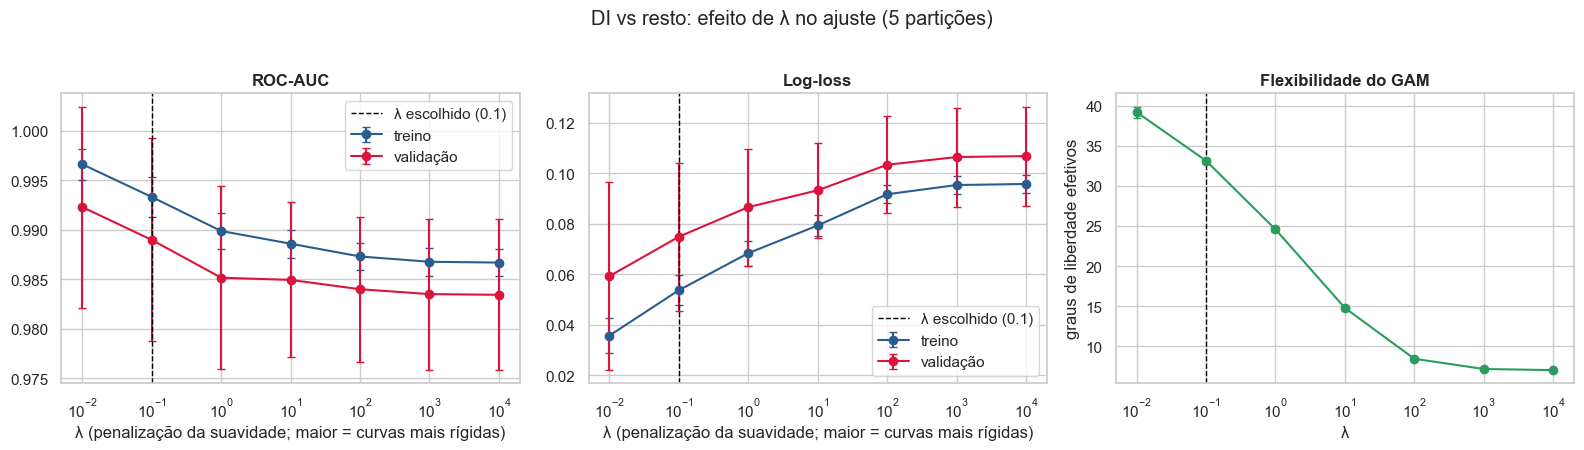

Log-loss           ROC-AUC           perda ROC-AUC (%)
parte      treino validação  treino validação                  
lambda                                                         
0.01       0.0357    0.0593  0.9966    0.9923            0.4340
0.10       0.0537    0.0749  0.9933    0.9890            0.4363
1.00       0.0684    0.0866  0.9899    0.9852            0.4768
10.00      0.0794    0.0933  0.9886    0.9849            0.3703
100.00     0.0918    0.1035  0.9873    0.9840            0.3353
1000.00    0.0954    0.1065  0.9868    0.9835            0.3312
10000.00   0.0958    0.1069  0.9867    0.9834            0.3300

In [18]:
LAMS = np.array([0.01, 0.1, 1, 10, 100, 1000, 10000])
yb_sel = (y_cv == selected_class).astype(int).values

sweep = []
for fold, (idx_tr, idx_va) in enumerate(cv.split(Xp, y_cv)):
    if fold >= 5:  # primeira repetição (5 partições disjuntas)
        break
    for lam in LAMS:
        g = LogisticGAM(build_terms(list(Xp.columns)), lam=lam, max_iter=200)
        g.fit(Xp.iloc[idx_tr].values, yb_sel[idx_tr])
        for part, idx in (("treino", idx_tr), ("validação", idx_va)):
            pr = g.predict_proba(Xp.iloc[idx].values)
            sweep.append({"lambda": lam, "parte": part, "fold": fold, "EDoF": g.statistics_["edof"],
                          "ROC-AUC": roc_auc_score(yb_sel[idx], pr), "Log-loss": log_loss(yb_sel[idx], pr)})
sweep = pd.DataFrame(sweep)

lam_chosen = float(gam_sel.lam[0][0])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, m in zip(axes[:2], ["ROC-AUC", "Log-loss"]):
    for part, color in (("treino", "#2b5c8f"), ("validação", "crimson")):
        s_ = sweep[sweep["parte"] == part].groupby("lambda")[m].agg(["mean", "std"])
        ax.errorbar(s_.index, s_["mean"], yerr=s_["std"], marker="o", color=color, capsize=3, label=part)
    ax.set_xscale("log")
    ax.axvline(lam_chosen, color="black", ls="--", lw=1, label=f"λ escolhido ({lam_chosen:g})")
    ax.set_xlabel("λ (penalização da suavidade; maior = curvas mais rígidas)")
    ax.set_title(m, fontweight="bold")
    ax.legend()
edof_s = sweep[sweep["parte"] == "treino"].groupby("lambda")["EDoF"].agg(["mean", "std"])
axes[2].errorbar(edof_s.index, edof_s["mean"], yerr=edof_s["std"], marker="o", color="#2a9d5c", capsize=3)
axes[2].set_xscale("log")
axes[2].axvline(lam_chosen, color="black", ls="--", lw=1)
axes[2].set_xlabel("λ")
axes[2].set_ylabel("graus de liberdade efetivos")
axes[2].set_title("Flexibilidade do GAM", fontweight="bold")
fig.suptitle(f"{selected_class} vs resto: efeito de λ no ajuste (5 partições)", y=1.02)
plt.tight_layout()
plt.show()

wide_sw = sweep.pivot_table(index="lambda", columns="parte", values=["ROC-AUC", "Log-loss"], aggfunc="mean")
wide_sw["perda ROC-AUC (%)"] = 100 * (wide_sw[("ROC-AUC", "treino")] - wide_sw[("ROC-AUC", "validação")]) / wide_sw[("ROC-AUC", "treino")]
display(wide_sw.round(4))


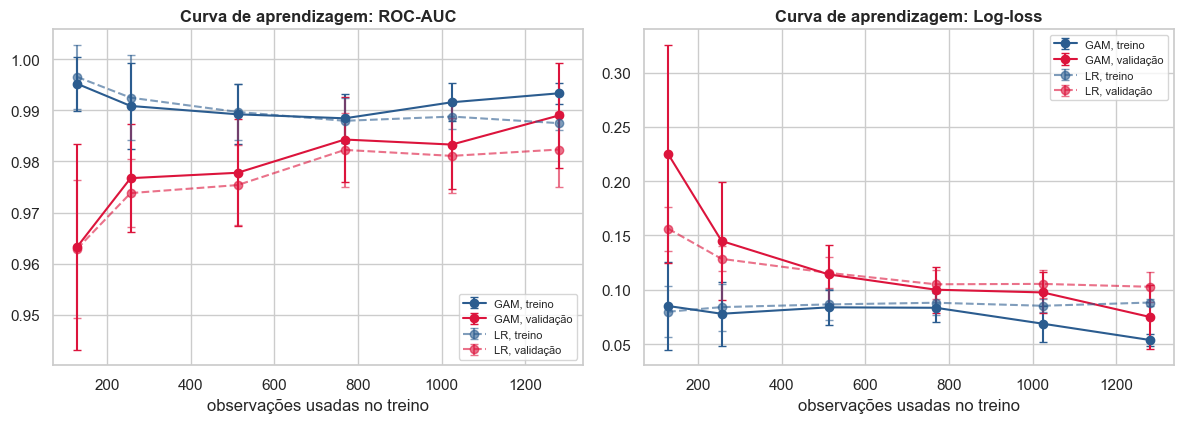

Avisos de não convergência do pygam (soma das 5 partições, por tamanho de treino): {128: 5, 256: 0, 512: 0, 768: 0, 1024: 0, 1280: 0}


Log-loss           ROC-AUC          
parte      treino validação  treino validação
n treino                                     
128        0.0851    0.2252  0.9952    0.9633
256        0.0779    0.1449  0.9909    0.9767
512        0.0838    0.1141  0.9892    0.9778
768        0.0834    0.1001  0.9884    0.9843
1024       0.0687    0.0975  0.9916    0.9833
1280       0.0537    0.0749  0.9933    0.9890

In [19]:
import contextlib
import io

FRACS = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
lc, not_converged = [], {}
for fold, (idx_tr, idx_va) in enumerate(cv.split(Xp, y_cv)):
    if fold >= 5:
        break
    for frac in FRACS:
        if frac < 1.0:
            sub, _ = train_test_split(idx_tr, train_size=frac, stratify=yb_sel[idx_tr], random_state=RANDOM_STATE)
        else:
            sub = idx_tr
        log = io.StringIO()
        with contextlib.redirect_stdout(log):
            g = fit_gam(Xp.iloc[sub], yb_sel[sub])
        not_converged[len(sub)] = not_converged.get(len(sub), 0) + log.getvalue().count("did not converge")
        m_lr = make_lr().fit(Xp.iloc[sub], yb_sel[sub])
        for name, model in (("GAM", g), ("LR", m_lr)):
            for part, idx in (("treino", sub), ("validação", idx_va)):
                Xi = Xp.iloc[idx].values if name == "GAM" else Xp.iloc[idx]
                pr = model.predict_proba(Xi) if name == "GAM" else model.predict_proba(Xi)[:, 1]
                lc.append({"n treino": len(sub), "modelo": name, "parte": part, "fold": fold,
                           "ROC-AUC": roc_auc_score(yb_sel[idx], pr), "Log-loss": log_loss(yb_sel[idx], pr)})
lc = pd.DataFrame(lc)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, m in zip(axes, ["ROC-AUC", "Log-loss"]):
    for (name, part), grp in lc.groupby(["modelo", "parte"]):
        s_ = grp.groupby("n treino")[m].agg(["mean", "std"])
        ax.errorbar(s_.index, s_["mean"], yerr=s_["std"], capsize=3, marker="o",
                    ls="-" if name == "GAM" else "--", color="#2b5c8f" if part == "treino" else "crimson",
                    alpha=1 if name == "GAM" else 0.6, label=f"{name}, {part}")
    ax.set_xlabel("observações usadas no treino")
    ax.set_title(f"Curva de aprendizagem: {m}", fontweight="bold")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Avisos de não convergência do pygam (soma das 5 partições, por tamanho de treino):", not_converged)
display(lc[lc["modelo"] == "GAM"].pivot_table(index="n treino", columns="parte", values=["ROC-AUC", "Log-loss"]).round(4))


Ajustes que não convergiram (ignorados): 1 [(5, 'GAM com λ fixo = 0.1')]


mean               std  \
parte                                               treino validação  treino   
modelo                                                                         
GAM com λ escolhido (grelha), etiquetas baralhadas  0.5599    0.5178  0.0179   
GAM com λ fixo = 0.1, etiquetas baralhadas          0.6396    0.4908  0.0119   
GAM só com HbA1c                                    0.9822    0.9822  0.0015   
LR só com HbA1c                                     0.9822    0.9822  0.0015   
GAM completo (16 preditores)                        0.9933    0.9885  0.0016   

                                                              
parte                                              validação  
modelo                                                        
GAM com λ escolhido (grelha), etiquetas baralhadas    0.0309  
GAM com λ fixo = 0.1, etiquetas baralhadas            0.0479  
GAM só com HbA1c                                      0.0059  
LR só com HbA1c                                       0.0059  
GAM completo (16 preditores)                          0.0078

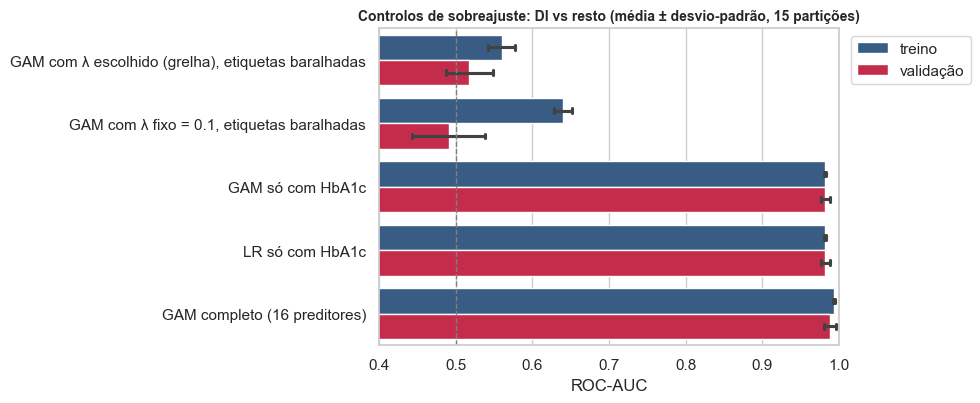

In [20]:
rows = []
perm = {r: np.random.RandomState(r).permutation(yb_sel) for r in range(3)}  # uma permutação das etiquetas por repetição
failed = []
for fold, (idx_tr, idx_va) in enumerate(cv.split(Xp, y_cv)):
    # Controlo 1: etiquetas baralhadas (treino e validação) -> não há sinal a aprender
    yp = perm[fold // 5]
    for name, make in (("GAM com λ escolhido (grelha)", lambda a, b: fit_gam(a, b)),
                       (f"GAM com λ fixo = {lam_chosen:g}", lambda a, b: LogisticGAM(build_terms(list(a.columns)), lam=lam_chosen, max_iter=200).fit(a.values, b))):
        try:
            g_sh = make(Xp.iloc[idx_tr], yp[idx_tr])
        except Exception as err:
            failed.append((fold, name))  # o pygam pode divergir (PIRLS) com λ muito pequeno
            continue
        for part, idx in (("treino", idx_tr), ("validação", idx_va)):
            rows.append({"modelo": f"{name}, etiquetas baralhadas", "parte": part,
                         "ROC-AUC": roc_auc_score(yp[idx], g_sh.predict_proba(Xp.iloc[idx].values))})

    # Controlo 2: só a HbA1c
    X1 = Xp[["HbA1c_level"]]
    g1 = fit_gam(X1.iloc[idx_tr], yb_sel[idx_tr])
    lr1 = make_lr().fit(X1.iloc[idx_tr], yb_sel[idx_tr])
    for name, model, is_gam in (("GAM só com HbA1c", g1, True), ("LR só com HbA1c", lr1, False)):
        for part, idx in (("treino", idx_tr), ("validação", idx_va)):
            pr = model.predict_proba(X1.iloc[idx].values) if is_gam else model.predict_proba(X1.iloc[idx])[:, 1]
            rows.append({"modelo": name, "parte": part, "ROC-AUC": roc_auc_score(yb_sel[idx], pr)})

# Referência: GAM completo (já calculado na validação cruzada)
full = pd.concat([
    cv_train[(cv_train["classe"] == selected_class) & (cv_train["modelo"] == "GAM")].assign(parte="treino"),
    cv_results[(cv_results["classe"] == selected_class) & (cv_results["modelo"] == "GAM")].assign(parte="validação"),
])
for part, grp in full.groupby("parte"):
    for v in grp["ROC-AUC"]:
        rows.append({"modelo": f"GAM completo ({len(predictors)} preditores)", "parte": part, "ROC-AUC": v})
ctrl = pd.DataFrame(rows)
print(f"Ajustes que não convergiram (ignorados): {len(failed)}", failed)

order = [f"GAM com λ escolhido (grelha), etiquetas baralhadas", f"GAM com λ fixo = {lam_chosen:g}, etiquetas baralhadas",
         "GAM só com HbA1c", "LR só com HbA1c", f"GAM completo ({len(predictors)} preditores)"]
summary = ctrl.groupby(["modelo", "parte"])["ROC-AUC"].agg(["mean", "std"]).unstack("parte").loc[order]
display(summary.round(4))

fig, ax = plt.subplots(figsize=(10, 4.2))
sns.barplot(data=ctrl, y="modelo", x="ROC-AUC", hue="parte", order=order, errorbar="sd",
            palette={"treino": "#2b5c8f", "validação": "crimson"}, capsize=0.15, ax=ax)
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_xlim(0.4, 1.0)
ax.set_title(f"Controlos de sobreajuste: {selected_class} vs resto (média ± desvio-padrão, 15 partições)", fontweight="bold", fontsize=10)
ax.set_ylabel("")
ax.legend(title="", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()



**Leitura.**

*Efeito de $\lambda$.* O valor escolhido pela grelha (0,1) é o mais baixo da grelha. O gráfico mostra que a perda treino-validação do ROC-AUC é de 0,3% a 0,5% para todos os $\lambda$ testados (tabela), e que a `Log-loss` de validação continua a melhorar quando $\lambda$ desce (0,075 com $\lambda$ = 0,1 e 0,059 com $\lambda$ = 0,01), apesar de o modelo ficar mais flexível (EDoF de 7 a 39). A distância entre a `Log-loss` de treino e a de validação cresce um pouco com a flexibilidade (0,011 com $\lambda$ muito grande, 0,021 com $\lambda$ = 0,1), como se espera, mas a validação não piora. Logo, $\lambda$ = 0,1 não provoca sobreajuste e a grelha é, se alguma coisa, conservadora.

*Curva de aprendizagem.* Com poucas observações o GAM ajusta bem o treino mas generaliza pior (ROC-AUC 0,995 no treino e 0,963 na validação com 128 observações, perda de 3,2%); com mais dados a distância fecha (0,993 contra 0,989 com 1280 observações, 0,4%) e a curva de validação ainda sobe, o que indica que o modelo beneficia de mais dados e não que esteja a decorar. Com 128 observações os 5 ajustes atingiram o máximo de iterações (aviso do `pygam`), pelo que esse primeiro ponto é o menos fiável.

*Controlos.* Com as etiquetas baralhadas não há nada a aprender. O GAM com o $\lambda$ escolhido pela grelha também não aprende (ROC-AUC 0,56 no treino e 0,52 na validação), porque o `gridsearch` responde com o $\lambda$ máximo, 1000. Forçando $\lambda$ = 0,1 o GAM já consegue decorar algum ruído (0,64 no treino), mas na validação fica ao nível do acaso (0,49). (Um dos 15 ajustes com $\lambda$ fixo não convergiu e foi ignorado.) Ou seja, o modelo tem capacidade para sobreajustar e é a validação que o denuncia; com as etiquetas verdadeiras o ROC-AUC de validação é 0,989, muito acima do acaso, pelo que o desempenho não é memorização.

*Porque é que o desempenho em `DI` é tão alto.* Um GAM só com `HbA1c_level` já tem ROC-AUC 0,982, igual no treino e na validação e igual ao da regressão logística, porque o ROC-AUC só depende da ordenação dos casos e a curva é quase monótona. Os outros 15 preditores acrescentam só 0,006 (de 0,982 para 0,989). É a quase separação por `HbA1c` vista em 6.2, não sobreajuste: `DI` é, na prática, a classe de `HbA1c` alta. Nas outras duas hipóteses, onde não há uma variável assim, o desempenho é bem mais modesto (ROC-AUC 0,87).

*Conclusão.* O critério dos 10% cumpre-se com folga (perda máxima de 4,0% na validação e 2,4% no teste), a validação não piora com modelos mais flexíveis, os controlos mostram que o modelo não memoriza ruído e o desempenho elevado em `DI` vem de um sinal real e muito forte numa só variável. O resultado depende de a indicação do professor ser a lida aqui (perda relativa de 10%); se o critério for outro, a tabela da secção 6.4 permite recalcular.


## Conclusões da Tarefa 6


- **Preditores:** o Lasso da tarefa 5 (`C = 0.05`, escolhido por validação cruzada) mantém 18 variáveis, 16 depois de retiradas as redundantes da idade.
- **Modelo escolhido:** `DI vs resto`, com o maior ROC-AUC na validação cruzada (0,988, contra 0,869 e 0,868) e vantagem em todas as métricas.
- **Efeitos estimados:** `HbA1c_level` domina (amplitude de cerca de 39 unidades de logit, quase uma reta); `age`, `blood_pressure` e `triglycerides` são os seguintes e compatíveis com retas. A não linearidade está repartida por várias variáveis e nenhuma, fora da `HbA1c`, é individualmente necessária; `alcohol_intake` tem forma de U (mesma média, maior desvio-padrão em `DI`), que a EDA, baseada em testes de localização, não detetava.
- **GAM contra regressão logística:** a `Log-loss` é significativamente melhor no GAM (0,074 contra 0,103, 15 em 15 partições) e a PR-AUC também; o ROC-AUC é um pouco melhor (0,989 contra 0,982) mas sem significância (p = 0,053). Um termo quadrático em `alcohol_intake` recupera só cerca de 20% do ganho.
- **Sobreajuste:** a perda relativa treino-validação é no máximo 4,0% (critério: 10%) e no teste 2,4%; a validação não piora com $\lambda$ menores, a curva de aprendizagem fecha com mais dados e, com etiquetas baralhadas, a validação fica ao nível do acaso. O desempenho elevado em `DI` vem da `HbA1c` (sozinha, ROC-AUC 0,982), não de memorização.
- **Ressalvas:** quase separação por `HbA1c`, seleção de preditores feita no treino todo, só 66 `DI` no teste, p-values aproximados (teste t corrigido; os do `pygam` não são fiáveis) e critério dos 10% baseado numa indicação oral.
